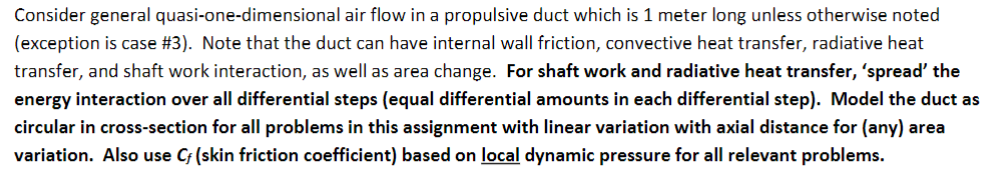

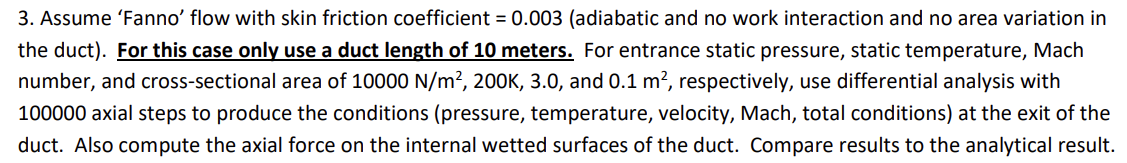

In [1]:
import numpy as np
from quasi_1D import quasi_1D_flow
import matplotlib.pyplot as plt

import scipy as sp


In [4]:
Cp = 1004.5
R = 287
gamma = 1.4

# Numerical

In [2]:
Pi = 100_000
Ti = 200
Mi = 3.0
ui = Mi * np.sqrt(1.4*287*Ti)
Cf = 0.003

L_tube = 10
axial_steps = 900_000

Ai = 0.1
Ae = Ai

xlist = np.linspace(0,L_tube,axial_steps+1)
Af = lambda x: Ai

[uout,Tout,Pout], M, x_break, A_break, Thrust = quasi_1D_flow(inlet = [ui,Ti,Pi], Af = Af,N = axial_steps,Cf=Cf)



In [3]:
gamma = 1.4
Tt = Tout*(1+(gamma-1)/2*M**2)
Pt = Pout*(1+(gamma-1)/2*M**2)**(gamma/(gamma-1))


print(f'exit Mach =             {M[-1]}')
print(f'exit Velocity =         {uout[-1]} m/s\n')

print(f'exit Temp =             {Tout[-1]} k')
print(f'exit Total Temp =       {Tt[-1]} k\n')

print(f'exit Pressure =         {Pout[-1]} Pa')
print(f'exit Total Pressure =   {Pt[-1]} Pa\n')

# print(f'exit end area = {A_break}')
print(f'{Thrust =                } N')


exit Mach =             2.792890975192477
exit Velocity =         827.997276687448 m/s

exit Temp =             218.74589863493748 k
exit Total Temp =       560.0000002784567 k

exit Pressure =         112336.84751670896 Pa
exit Total Pressure =   3015717.1863988633 Pa

Thrust =                123761.13763413618 N


# Analytical

In [37]:
print(f'exit Mach =             {Me}')
print(f'exit Velocity =         {ue} m/s\n')

print(f'exit Temp =             {Te} k')
print(f'exit Total Temp =       {Tte} k\n')

print(f'exit Pressure =         {Pe} Pa')
print(f'exit Total Pressure =   {Pte} Pa\n')

print(f'{Thrust_a =              } N')

exit Mach =             0.21758529845936578
exit Velocity =         77.19434835632437 m/s

exit Temp =             313.257863903356 k
exit Total Temp =       316.22399999999993 k

exit Pressure =         135987.76711331183 Pa
exit Total Pressure =   140548.04299085928 Pa

Thrust_a =              26088.592617226546 N


# Error

In [38]:
print(f'exit Mach error =           {M[-1]-Me}')
print(f'exit Velocity error =       {uout[-1]-ue} m/s\n')

print(f'exit Temp error =           {Tout[-1]-Te} k')
print(f'exit Total Temp error =     {Tt[-1]-Tte} k\n')

print(f'exit Pressure error =       {Pout[-1]-Pe} Pa')
print(f'exit Total Pressure error = {Pt[-1]-Pte} Pa\n')

# print(f'exit end area = {A_break}')
print(f'Thrust Error =              {Thrust - Thrust_a} N')

exit Mach error =           -3.700166343878486e-07
exit Velocity error =       -0.00012710590495146334 m/s

exit Temp error =           3.3824951970018446e-05 k
exit Total Temp error =     2.405705799901625e-05 k

exit Pressure error =       0.04082665144233033 Pa
exit Total Pressure error = 0.026502586202695966 Pa

Thrust Error =              0.003332895015773829 N


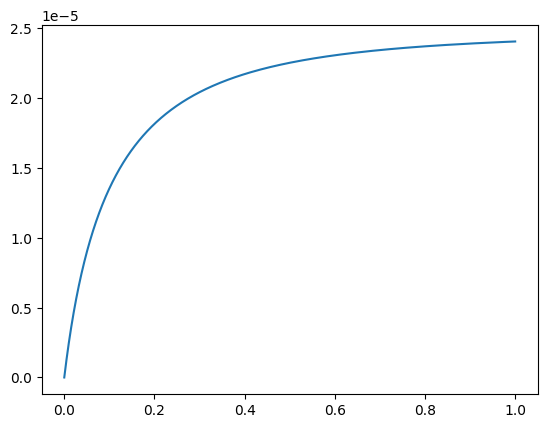

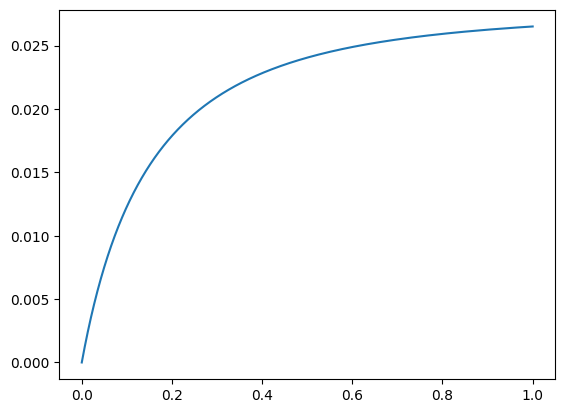

In [39]:
plt.figure('total temp error along x')
plt.plot(xlist,Tt-Tte)
plt.show()

plt.figure('total pressure error along x')
plt.plot(xlist,Pt-Pte)
plt.show()